In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from brokenbar import config, dsp, features, io, plotting

plotting.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

import json
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

runs, windows, _ = features.load_feature_tables()
print(f"{len(runs)} runs, {len(windows)} windows")

398 runs, 1194 windows


In [2]:
CURRENT = ["lsb_db", "usb_db", "rms", "slip"]
VIBRATION = [c for c in runs.columns if c.startswith("Vib_")]
FEATURE_SETS = {"current": CURRENT, "vibration": VIBRATION, "both": CURRENT + VIBRATION}

MODELS = {
    "logreg": make_pipeline(StandardScaler(),
                            LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced")),
    "forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced",
                                     random_state=0, n_jobs=-1),
}
TASKS = {"detection": "faulty", "severity": "n_bars"}
LOADS = sorted(runs.load_pct.unique())
# split by repetition: two whole repetitions held out per fold
CV = GroupKFold(n_splits=5)


# balanced accuracy at each load
def score_by_load(y, pred, loads):
    return pd.Series({L: balanced_accuracy_score(y[loads == L], pred[loads == L]) for L in LOADS})


# lowest load L such that every load >= L reaches the threshold
def lowest_reliable_load(scores, threshold):
    for L in LOADS:
        if (scores[[l for l in LOADS if l >= L]] >= threshold).all():
            return L
    return None

{name: len(cols) for name, cols in FEATURE_SETS.items()}

{'current': 4, 'vibration': 30, 'both': 34}

In [3]:
y_load = runs.load_pct.to_numpy()
records, oof = [], {}
for task, target in TASKS.items():
    y = runs[target].to_numpy()
    for sensors, cols in FEATURE_SETS.items():
        for model_name, model in MODELS.items():
            # out-of-fold predictions, grouped by repetition
            pred = cross_val_predict(clone(model), runs[cols], y, groups=runs.rep, cv=CV)
            oof[task, sensors, model_name] = pred
            records.append({"task": task, "sensors": sensors, "model": model_name,
                            "overall": balanced_accuracy_score(y, pred),
                            **score_by_load(y, pred, y_load)})
q1 = pd.DataFrame(records).set_index(["task", "sensors", "model"])
q1.to_csv(config.RESULTS_DIR / "ml_sensor_comparison.csv")
q1.round(3)

overall   12.5  25.0  37.5  50.0  62.5  75.0  87.5  100.0
task      sensors   model                                                            
detection current   logreg    0.992  0.938   1.0   1.0   1.0   1.0   1.0  1.00   1.00
                    forest    0.987  0.894   1.0   1.0   1.0   1.0   1.0  1.00   1.00
          vibration logreg    1.000  1.000   1.0   1.0   1.0   1.0   1.0  1.00   1.00
                    forest    1.000  1.000   1.0   1.0   1.0   1.0   1.0  1.00   1.00
          both      logreg    1.000  1.000   1.0   1.0   1.0   1.0   1.0  1.00   1.00
                    forest    1.000  1.000   1.0   1.0   1.0   1.0   1.0  1.00   1.00
severity  current   logreg    0.972  0.780   1.0   1.0   1.0   1.0   1.0  1.00   1.00
                    forest    0.982  0.898   1.0   1.0   1.0   1.0   1.0  0.98   0.98
          vibration logreg    1.000  1.000   1.0   1.0   1.0   1.0   1.0  1.00   1.00
                    forest    1.000  1.000   1.0   1.0   1.0   1.0   1.0  1.00   1.00
          both      logreg    1.000  1.000   1.0   1.0   1.0   1.0   1.0  1.00   1.00
                    forest    1.000  1.000   1.0   1.0   1.0   1.0   1.0  1.00   1.00

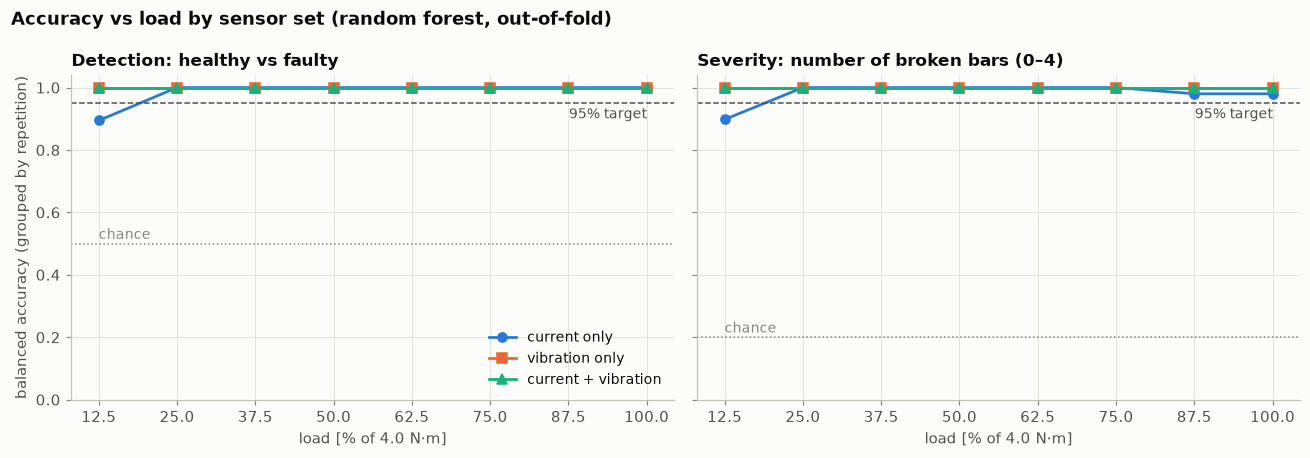

In [4]:
HEADLINE_MODEL = "forest"
THRESHOLDS = {"detection": 0.95, "severity": 0.95}
MARKERS = {"current": "o", "vibration": "s", "both": "^"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, task in zip(axes, TASKS):
    for sensors in FEATURE_SETS:
        s = q1.loc[(task, sensors, HEADLINE_MODEL), LOADS]
        ax.plot(LOADS, s.values, marker=MARKERS[sensors], lw=1.8,
                color=plotting.SENSOR_COLORS[sensors], label=f"{sensors} only" if sensors != "both" else "current + vibration")
    chance = 0.5 if task == "detection" else 0.2
    ax.axhline(THRESHOLDS[task], color=plotting.INK_2, ls="--", lw=1)
    ax.text(LOADS[-1], THRESHOLDS[task] - 0.015, f"{THRESHOLDS[task]:.0%} target", ha="right",
            va="top", fontsize=9, color=plotting.INK_2)
    ax.axhline(chance, color=plotting.MUTED, ls=":", lw=1)
    ax.text(LOADS[0], chance + 0.015, "chance", fontsize=9, color=plotting.MUTED)
    ax.set(xticks=LOADS, xlabel="load [% of 4.0 N·m]",
           title="Detection: healthy vs faulty" if task == "detection"
           else "Severity: number of broken bars (0–4)")
axes[0].set(ylabel="balanced accuracy (grouped by repetition)", ylim=(0, 1.04))
axes[0].legend(loc="lower right")
fig.suptitle(f"Accuracy vs load by sensor set (random forest, out-of-fold)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()

In [5]:
def fit_score(train, test, cols, target, model):
    m = clone(MODELS[model]).fit(train[cols], train[target])
    return balanced_accuracy_score(test[target], m.predict(test[cols]))

rows = []
high = runs[runs.load_pct >= 75]
for task, target in TASKS.items():
    for sensors, cols in FEATURE_SETS.items():
        for model in MODELS:
            for L in LOADS:
                # leave-one-load-out: train on the other seven loads
                test = runs[runs.load_pct == L]
                rows.append({"task": task, "sensors": sensors, "model": model, "scheme": "leave-one-load-out",
                             "load_pct": L, "score": fit_score(runs[runs.load_pct != L], test, cols, target, model)})
                # train on 75-100 % load only, test on lighter loads
                if L < 75:
                    rows.append({"task": task, "sensors": sensors, "model": model, "scheme": "train >=75% only",
                                 "load_pct": L, "score": fit_score(high, test, cols, target, model)})
q2 = pd.DataFrame(rows)
q2.to_csv(config.RESULTS_DIR / "ml_load_generalisation.csv", index=False)
q2.pivot_table(index=["task", "scheme", "sensors", "model"], columns="load_pct", values="score").round(2)

load_pct                                       12.5   25.0   37.5   50.0   62.5   75.0   87.5   100.0
task      scheme             sensors   model                                                         
detection leave-one-load-out both      forest   0.92   1.00   1.00   1.00   1.00    1.0   1.00   0.80
                                       logreg   1.00   1.00   1.00   1.00   1.00    1.0   1.00   1.00
                             current   forest   0.87   1.00   1.00   1.00   1.00    1.0   1.00   1.00
                                       logreg   0.95   1.00   1.00   1.00   1.00    1.0   1.00   1.00
                             vibration forest   1.00   1.00   1.00   1.00   1.00    1.0   1.00   0.80
                                       logreg   1.00   1.00   1.00   1.00   1.00    1.0   1.00   1.00
          train >=75% only   both      forest   0.88   0.94   1.00   1.00   1.00    NaN    NaN    NaN
                                       logreg   0.94   1.00   1.00   1.00   1.00    NaN    NaN    NaN
                             current   forest   0.75   0.88   0.88   1.00   1.00    NaN    NaN    NaN
                                       logreg   0.88   0.88   1.00   1.00   1.00    NaN    NaN    NaN
                             vibration forest   0.71   1.00   1.00   1.00   1.00    NaN    NaN    NaN
                                       logreg   0.89   0.85   0.95   1.00   1.00    NaN    NaN    NaN
severity  leave-one-load-out both      forest   0.78   1.00   1.00   1.00   1.00    1.0   1.00   1.00
                                       logreg   0.80   1.00   1.00   1.00   1.00    1.0   1.00   1.00
                             current   forest   0.46   0.40   0.40   0.60   0.98    1.0   0.98   0.88
                                       logreg   0.31   1.00   1.00   1.00   1.00    1.0   1.00   0.60
                             vibration forest   0.78   1.00   1.00   1.00   1.00    1.0   1.00   1.00
                                       logreg   0.76   1.00   1.00   1.00   1.00    1.0   1.00   1.00
          train >=75% only   both      forest   0.20   0.40   0.92   1.00   1.00    NaN    NaN    NaN
                                       logreg   0.48   0.80   0.80   1.00   1.00    NaN    NaN    NaN
                             current   forest   0.20   0.20   0.40   0.60   1.00    NaN    NaN    NaN
                                       logreg   0.20   0.40   0.80   0.84   1.00    NaN    NaN    NaN
                             vibration forest   0.20   0.20   0.82   1.00   1.00    NaN    NaN    NaN
                                       logreg   0.35   0.80   0.80   1.00   1.00    NaN    NaN    NaN

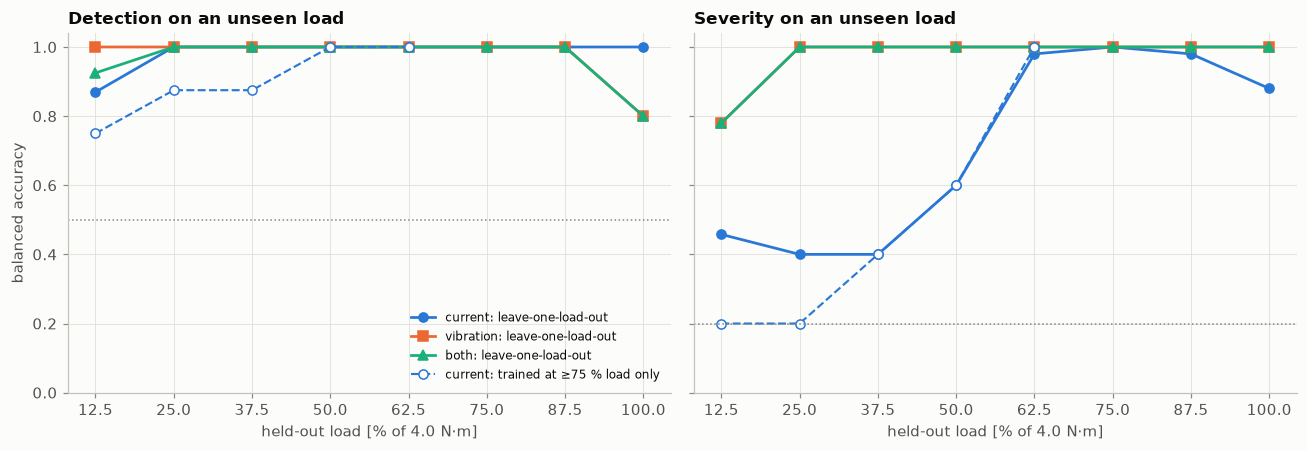

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, task in zip(axes, TASKS):
    for sensors in FEATURE_SETS:
        d = q2[(q2.task == task) & (q2.sensors == sensors) & (q2.model == HEADLINE_MODEL)
               & (q2.scheme == "leave-one-load-out")]
        ax.plot(d.load_pct, d.score, marker=MARKERS[sensors], lw=1.8, color=plotting.SENSOR_COLORS[sensors],
                label=f"{sensors}: leave-one-load-out")
    d = q2[(q2.task == task) & (q2.sensors == "current") & (q2.model == HEADLINE_MODEL)
           & (q2.scheme == "train >=75% only")]
    ax.plot(d.load_pct, d.score, marker="o", lw=1.4, ls="--", mfc=plotting.SURFACE,
            color=plotting.SENSOR_COLORS["current"], label="current: trained at ≥75 % load only")
    ax.axhline(0.5 if task == "detection" else 0.2, color=plotting.MUTED, ls=":", lw=1)
    ax.set(xticks=LOADS, xlabel="held-out load [% of 4.0 N·m]",
           title="Detection on an unseen load" if task == "detection" else "Severity on an unseen load")
axes[0].set(ylabel="balanced accuracy", ylim=(0, 1.04))
axes[0].legend(loc="lower right", fontsize=8)
fig.tight_layout()

severity errors: 7 of 398; off by exactly one bar: 100%
light load (12.5–25 %)  : healthy->faulty 1, faulty->healthy 4
load ≥ 37.5 %           : healthy->faulty 0, faulty->healthy 0


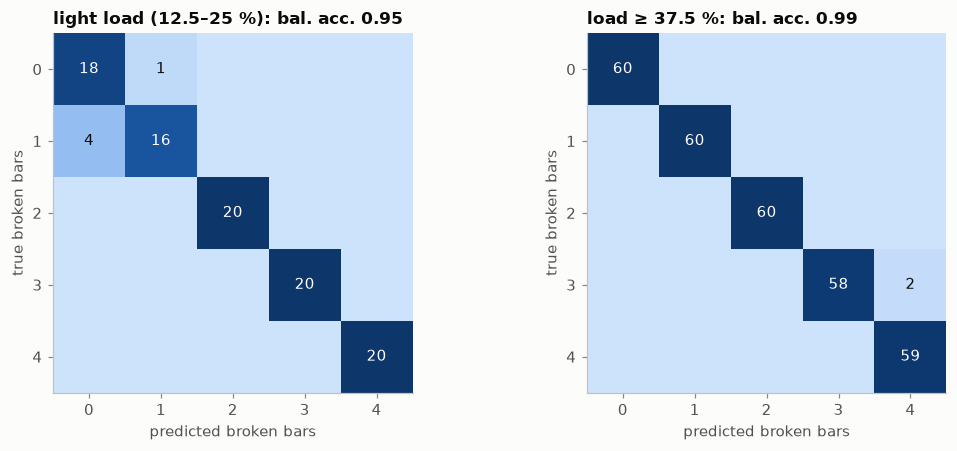

In [7]:
pred = oof["severity", "current", HEADLINE_MODEL]
y = runs.n_bars.to_numpy()
groups = {"light load (12.5–25 %)": y_load <= 25, "load ≥ 37.5 %": y_load > 25}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, mask) in zip(axes, groups.items()):
    cm = confusion_matrix(y[mask], pred[mask], labels=range(5))
    ax.imshow(cm, cmap=plotting.SEQUENTIAL, vmin=0, vmax=cm.sum(axis=1).max())
    for i in range(5):
        for j in range(5):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                        color="white" if cm[i, j] > 0.55 * cm.sum(axis=1).max() else plotting.INK)
    ax.set_xticks(range(5), range(5))
    ax.set_yticks(range(5), range(5))
    ax.grid(False)
    ax.set(xlabel="predicted broken bars", ylabel="true broken bars",
           title=f"{name}: bal. acc. {balanced_accuracy_score(y[mask], pred[mask]):.2f}")
fig.tight_layout()

# how many severity errors are off by exactly one bar
err = pred != y
print(f"severity errors: {err.sum()} of {len(y)}; "
      f"off by exactly one bar: {(np.abs(pred - y)[err] == 1).mean():.0%}")
for name, mask in groups.items():
    healthy_called_faulty = ((y == 0) & (pred > 0) & mask).sum()
    faulty_called_healthy = ((y > 0) & (pred == 0) & mask).sum()
    print(f"{name:24s}: healthy->faulty {healthy_called_faulty}, faulty->healthy {faulty_called_healthy}")

In [8]:
light = q1.loc[(slice(None), slice(None), HEADLINE_MODEL), [12.5, 25.0]].mean(axis=1)
full = q1.loc[(slice(None), slice(None), HEADLINE_MODEL), [87.5, 100.0]].mean(axis=1)
pd.DataFrame({"light load (12.5-25 %)": light, "heavy load (87.5-100 %)": full}).round(3)

light load (12.5-25 %)  heavy load (87.5-100 %)
task      sensors   model                                                  
detection current   forest                   0.947                     1.00
          vibration forest                   1.000                     1.00
          both      forest                   1.000                     1.00
severity  current   forest                   0.949                     0.98
          vibration forest                   1.000                     1.00
          both      forest                   1.000                     1.00

In [9]:
# same model on 5-s windows, three ways of splitting
wcols = ["lsb_db", "usb_db", "rms", "slip"]
schemes = {
    "random window split (leaky)": (StratifiedKFold(5, shuffle=True, random_state=0), None),
    "grouped by run": (GroupKFold(5), windows.run_id),
    "grouped by repetition": (GroupKFold(5), windows.rep),
}
light_w = windows.load_pct <= 25
rows = []
for name, (cv, groups) in schemes.items():
    p = cross_val_predict(clone(MODELS["forest"]), windows[wcols], windows.n_bars, groups=groups, cv=cv)
    rows.append({"split": name,
                 "severity, all loads": balanced_accuracy_score(windows.n_bars, p),
                 "severity, loads <= 25 %": balanced_accuracy_score(windows.n_bars[light_w], p[light_w])})
leak = pd.DataFrame(rows).set_index("split")
leak.to_csv(config.RESULTS_DIR / "ml_split_leakage.csv")
leak.round(3)

,"severity, all loads","severity, loads <= 25 %"
split,,
random window split (leaky),0.983,0.946
grouped by run,0.977,0.923
grouped by repetition,0.972,0.902


In [10]:
def curve(task, sensors, model=HEADLINE_MODEL):
    return q1.loc[(task, sensors, model), LOADS]

X = lowest_reliable_load(curve("detection", "current"), THRESHOLDS["detection"])
Y = lowest_reliable_load(curve("severity", "current"), THRESHOLDS["severity"])
summary = {
    "model": HEADLINE_MODEL,
    "thresholds": THRESHOLDS,
    "detect_current_min_load_pct": X,
    "severity_current_min_load_pct": Y,
    "detect_vibration_min_load_pct": lowest_reliable_load(curve("detection", "vibration"), THRESHOLDS["detection"]),
    "severity_vibration_min_load_pct": lowest_reliable_load(curve("severity", "vibration"), THRESHOLDS["severity"]),
    "detect_both_min_load_pct": lowest_reliable_load(curve("detection", "both"), THRESHOLDS["detection"]),
    "severity_both_min_load_pct": lowest_reliable_load(curve("severity", "both"), THRESHOLDS["severity"]),
    "per_load": {f"{t}/{s}": curve(t, s).round(3).to_dict() for t in TASKS for s in FEATURE_SETS},
    "overall": {f"{t}/{s}": round(q1.loc[(t, s, HEADLINE_MODEL), "overall"], 3)
                for t in TASKS for s in FEATURE_SETS},
}
with open(config.RESULTS_DIR / "summary.json", "w") as fh:
    json.dump(summary, fh, indent=2)

print(f"Broken bars were detectable from stator current alone at >= {X:g} % load "
      f"(balanced accuracy >= {THRESHOLDS['detection']:.0%} at every load from there up), "
      f"with severity (0-4 bars) estimable at >= {Y:g} % load "
      f"(>= {THRESHOLDS['severity']:.0%}).")
json.dumps({k: v for k, v in summary.items() if k.endswith("load_pct")}, indent=1)

Broken bars were detectable from stator current alone at >= 25 % load (balanced accuracy >= 95% at every load from there up), with severity (0-4 bars) estimable at >= 25 % load (>= 95%).


'{\n "detect_current_min_load_pct": 25.0,\n "severity_current_min_load_pct": 25.0,\n "detect_vibration_min_load_pct": 12.5,\n "severity_vibration_min_load_pct": 12.5,\n "detect_both_min_load_pct": 12.5,\n "severity_both_min_load_pct": 12.5\n}'